In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
print("CUDA available:", torch.cuda.is_available())

C:\Users\Steve\retina_severity_project\retina_env\Lib\site-packages\albumentations\__init__.py:13: UserWarning: A new version of Albumentations is available: 2.0.8 (you have 1.4.18). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()


Using device: cuda
CUDA available: True


In [2]:
eyepacs_csv = r"C:\Users\Steve\retina_severity_project\data\raw\eyepacs\trainLabels_cropped.csv"
eyepacs_img_dir = r"C:\Users\Steve\retina_severity_project\data\raw\eyepacs\resized_train_cropped"
eyepacs_df = pd.read_csv(eyepacs_csv)
eyepacs_df_clean = eyepacs_df[['image', 'level']].copy()
eyepacs_df_clean.columns = ['id_code', 'diagnosis']
eyepacs_df_clean['filepath'] = eyepacs_df_clean['id_code'].apply(lambda x: os.path.join(eyepacs_img_dir, x + '.jpeg'))
eyepacs_df_clean['source'] = 'eyepacs'

aptos_csv = r"C:\Users\Steve\retina_severity_project\data\raw\train.csv"
aptos_img_dir = r"C:\Users\Steve\retina_severity_project\data\raw\train_images"
aptos_df = pd.read_csv(aptos_csv)
aptos_df_clean = aptos_df[['id_code', 'diagnosis']].copy()
aptos_df_clean['filepath'] = aptos_df_clean['id_code'].apply(lambda x: os.path.join(aptos_img_dir, x + '.png'))
aptos_df_clean['source'] = 'aptos'

combined_df = pd.concat([aptos_df_clean, eyepacs_df_clean], ignore_index=True)
print("Combined total:", len(combined_df))

Combined total: 38770


In [3]:
csv_path = r"C:\Users\Steve\Downloads\aptos2019-blindness-detection\train.csv"

if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    print("CSV loaded successfully!")
    print("Shape:", df.shape)
    print(df.head())
    print("\nClass distribution:")
    print(df['diagnosis'].value_counts().sort_index())
else:
    print("CSV not found yet at:", csv_path)

CSV loaded successfully!
Shape: (3662, 2)
        id_code  diagnosis
0  000c1434d8d7          2
1  001639a390f0          4
2  0024cdab0c1e          1
3  002c21358ce6          0
4  005b95c28852          0

Class distribution:
diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64


In [4]:
img_dir = r"C:\Users\Steve\retina_severity_project\data\raw\train_images"
csv_path = r"C:\Users\Steve\retina_severity_project\data\raw\train.csv"

df = pd.read_csv(csv_path)
print("CSV loaded. Shape:", df.shape)

image_files = os.listdir(img_dir)
print("Number of images:", len(image_files))
print("First few filenames:", image_files[:5])

CSV loaded. Shape: (3662, 2)
Number of images: 3662
First few filenames: ['000c1434d8d7.png', '001639a390f0.png', '0024cdab0c1e.png', '002c21358ce6.png', '005b95c28852.png']


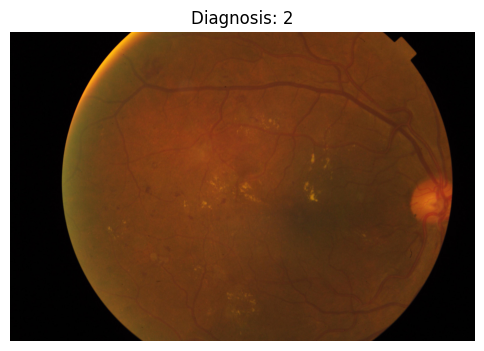

Image shape: (2136, 3216, 3)


In [5]:
sample_id = df.iloc[0]['id_code']
sample_label = df.iloc[0]['diagnosis']

img_path = os.path.join(img_dir, sample_id + '.png')
img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.title(f"Diagnosis: {sample_label}")
plt.axis('off')
plt.show()

print("Image shape:", img.shape)

In [6]:
img_dir = r"C:\Users\Steve\retina_severity_project\data\raw\train_images"
csv_path = r"C:\Users\Steve\retina_severity_project\data\raw\train.csv"
df = pd.read_csv(csv_path)
print("Reloaded from new location. Shape:", df.shape)

Reloaded from new location. Shape: (3662, 2)


In [5]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df['diagnosis']
)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("\nTrain class distribution:")
print(train_df['diagnosis'].value_counts().sort_index())
print("\nVal class distribution:")
print(val_df['diagnosis'].value_counts().sort_index())

Task was destroyed but it is pending!
task: <Task pending name='Task-1077' coro=<_async_in_context.<locals>.run_in_context() done, defined at C:\Users\Steve\retina_severity_project\retina_env\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-1078' coro=<Kernel.shell_main() running at C:\Users\Steve\retina_severity_project\retina_env\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\Steve\retina_severity_project\retina_env\Lib\site-packages\zmq\eventloop\zmqstream.py:564]>
C:\Users\Steve\retina_severity_project\retina_env\Lib\site-packages\pygments\style.py:98: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  for styledef in obj.styles.get(token, '').split():
Task was destroyed but it is pending!
task: <Task pending name='Task-1078' coro=<Kernel.shell_main() running at C:\Users\Steve\retina_severity_project\retina_env\Lib\site-packages\ipykernel\kernelbase.py:597

NameError: name 'df' is not defined

In [8]:
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A

IMG_SIZE = 224

train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.RandomBrightnessContrast(p=0.3),
])

val_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
])

class RetinaDataset(Dataset):
    def __init__(self, dataframe, img_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = os.path.join(self.img_dir, row['id_code'] + '.png')
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        if self.transform:
            img = self.transform(image=img)['image']

        img = img / 255.0
        img = img.transpose(2, 0, 1)
        img = torch.tensor(img, dtype=torch.float32)

        label = torch.tensor(row['diagnosis'], dtype=torch.long)

        return img, label

train_dataset = RetinaDataset(train_df, img_dir, transform=train_transform)
val_dataset = RetinaDataset(val_df, img_dir, transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)

print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))

sample_imgs, sample_labels = next(iter(train_loader))
print("Batch image shape:", sample_imgs.shape)
print("Batch label shape:", sample_labels.shape)
print("Sample labels:", sample_labels[:5])

C:\Users\Steve\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Number of training batches: 184
Number of validation batches: 46
Batch image shape: torch.Size([16, 3, 224, 224])
Batch label shape: torch.Size([16])
Sample labels: tensor([2, 2, 2, 2, 0])


In [9]:
import timm

model = timm.create_model('resnet34', pretrained=False, num_classes=5)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print("Model created and moved to:", device)
print("Total parameters:", sum(p.numel() for p in model.parameters()))

Model created and moved to: cuda
Total parameters: 21287237


In [10]:
import torch.nn as nn
import torch.optim as optim
import numpy as np

class_counts = train_df['diagnosis'].value_counts().sort_index().values
class_weights = 1.0 / class_counts
class_weights = class_weights / class_weights.sum() * len(class_counts)
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

print("Class counts:", class_counts)
print("Class weights:", class_weights)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(model.parameters(), lr=1e-4)

print("\nLoss function and optimizer ready")

Class counts: [1444  296  799  154  236]
Class weights: tensor([0.2157, 1.0522, 0.3898, 2.0225, 1.3198], device='cuda:0')

Loss function and optimizer ready


In [11]:
import time

NUM_EPOCHS = 15
train_losses = []
val_losses = []
val_accuracies = []

for epoch in range(NUM_EPOCHS):
    start_time = time.time()

    model.train()
    running_train_loss = 0.0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item()
    avg_train_loss = running_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    model.eval()
    running_val_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            running_val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    avg_val_loss = running_val_loss / len(val_loader)
    val_accuracy = correct / total
    val_losses.append(avg_val_loss)
    val_accuracies.append(val_accuracy)

    elapsed = time.time() - start_time
    print(f"Epoch {epoch+1}/{NUM_EPOCHS} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Accuracy: {val_accuracy:.4f} | Time: {elapsed:.1f}s")

Epoch 1/15 | Train Loss: 1.4763 | Val Loss: 1.3627 | Val Accuracy: 0.5498 | Time: 305.8s
Epoch 2/15 | Train Loss: 1.3200 | Val Loss: 1.2832 | Val Accuracy: 0.5566 | Time: 344.1s
Epoch 3/15 | Train Loss: 1.2638 | Val Loss: 1.2473 | Val Accuracy: 0.6508 | Time: 343.6s
Epoch 4/15 | Train Loss: 1.2121 | Val Loss: 1.2359 | Val Accuracy: 0.6371 | Time: 328.2s
Epoch 5/15 | Train Loss: 1.2022 | Val Loss: 1.2349 | Val Accuracy: 0.6835 | Time: 668.6s
Epoch 6/15 | Train Loss: 1.1816 | Val Loss: 1.2471 | Val Accuracy: 0.6330 | Time: 360.9s
Epoch 7/15 | Train Loss: 1.1910 | Val Loss: 1.2516 | Val Accuracy: 0.6344 | Time: 336.6s
Epoch 8/15 | Train Loss: 1.1650 | Val Loss: 1.1793 | Val Accuracy: 0.6494 | Time: 330.6s
Epoch 9/15 | Train Loss: 1.1633 | Val Loss: 1.1822 | Val Accuracy: 0.6903 | Time: 329.5s
Epoch 10/15 | Train Loss: 1.1454 | Val Loss: 1.3512 | Val Accuracy: 0.5553 | Time: 327.3s
Epoch 11/15 | Train Loss: 1.1450 | Val Loss: 1.1884 | Val Accuracy: 0.6480 | Time: 324.4s
Epoch 12/15 | Train

In [12]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for imgs, labels in val_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']))

               precision    recall  f1-score   support

        No DR       0.92      0.93      0.93       361
         Mild       0.34      0.54      0.42        74
     Moderate       0.66      0.58      0.62       200
       Severe       0.26      0.33      0.29        39
Proliferative       0.28      0.12      0.17        59

     accuracy                           0.70       733
    macro avg       0.49      0.50      0.49       733
 weighted avg       0.71      0.70      0.70       733



In [13]:
torch.save(model.state_dict(), r"C:\Users\Steve\retina_severity_project\models\retina_severity_v1.pth")
print("Model saved successfully")

Model saved successfully


In [14]:
report_text = classification_report(all_labels, all_preds, target_names=['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative'])

with open(r"C:\Users\Steve\retina_severity_project\outputs\classification_report.txt", "w") as f:
    f.write(report_text)

print("Classification report saved")

Classification report saved


In [3]:
eyepacs_csv = r"C:\Users\Steve\retina_severity_project\data\raw\eyepacs\trainLabels_cropped.csv"
eyepacs_df = pd.read_csv(eyepacs_csv)
print("Shape:", eyepacs_df.shape)
print(eyepacs_df.head())
print("\nColumns:", eyepacs_df.columns.tolist())

Shape: (35108, 4)
   Unnamed: 0.1  Unnamed: 0     image  level
0             0           0   10_left      0
1             1           1  10_right      0
2             2           2   13_left      0
3             3           3  13_right      0
4             4           4   15_left      1

Columns: ['Unnamed: 0.1', 'Unnamed: 0', 'image', 'level']


In [5]:
eyepacs_img_dir = r"C:\Users\Steve\retina_severity_project\data\raw\eyepacs\resized_train_cropped\resized_train_cropped"

sample_files = os.listdir(eyepacs_img_dir)[:5]
print("Sample filenames:", sample_files)

Sample filenames: ['10003_left.jpeg', '10003_right.jpeg', '10007_left.jpeg', '10007_right.jpeg', '10009_left.jpeg']


In [6]:
# Standardize EyePACS
eyepacs_df_clean = eyepacs_df[['image', 'level']].copy()
eyepacs_df_clean.columns = ['id_code', 'diagnosis']
eyepacs_df_clean['filepath'] = eyepacs_df_clean['id_code'].apply(
    lambda x: os.path.join(eyepacs_img_dir, x + '.jpeg')
)
eyepacs_df_clean['source'] = 'eyepacs'

# Standardize APTOS (reload to be safe)
aptos_csv = r"C:\Users\Steve\retina_severity_project\data\raw\train.csv"
aptos_img_dir = r"C:\Users\Steve\retina_severity_project\data\raw\train_images"
aptos_df = pd.read_csv(aptos_csv)
aptos_df_clean = aptos_df[['id_code', 'diagnosis']].copy()
aptos_df_clean['filepath'] = aptos_df_clean['id_code'].apply(
    lambda x: os.path.join(aptos_img_dir, x + '.png')
)
aptos_df_clean['source'] = 'aptos'

# Combine
combined_df = pd.concat([aptos_df_clean, eyepacs_df_clean], ignore_index=True)

print("APTOS samples:", len(aptos_df_clean))
print("EyePACS samples:", len(eyepacs_df_clean))
print("Combined total:", len(combined_df))
print("\nCombined class distribution:")
print(combined_df['diagnosis'].value_counts().sort_index())
print("\nSample rows:")
print(combined_df.head())
print(combined_df.tail())


APTOS samples: 3662
EyePACS samples: 35108
Combined total: 38770

Combined class distribution:
diagnosis
0    27607
1     2808
2     6287
3     1065
4     1003
Name: count, dtype: int64

Sample rows:
        id_code  diagnosis                                           filepath  \
0  000c1434d8d7          2  C:\Users\Steve\retina_severity_project\data\ra...   
1  001639a390f0          4  C:\Users\Steve\retina_severity_project\data\ra...   
2  0024cdab0c1e          1  C:\Users\Steve\retina_severity_project\data\ra...   
3  002c21358ce6          0  C:\Users\Steve\retina_severity_project\data\ra...   
4  005b95c28852          0  C:\Users\Steve\retina_severity_project\data\ra...   

  source  
0  aptos  
1  aptos  
2  aptos  
3  aptos  
4  aptos  
           id_code  diagnosis  \
38765  44347_right          0   
38766   44348_left          0   
38767  44348_right          0   
38768   44349_left          0   
38769  44349_right          1   

                                                

In [7]:
sample_row = eyepacs_df_clean.iloc[0]
img = cv2.imread(sample_row['filepath'])
print("Loaded successfully:", img is not None)
if img is not None:
    print("Shape:", img.shape)

Loaded successfully: True
Shape: (1024, 1024, 3)


In [4]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    combined_df, test_size=0.15, random_state=42, stratify=combined_df['diagnosis']
)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))

Training samples: 32954
Validation samples: 5816


In [9]:
class CombinedRetinaDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = cv2.imread(row['filepath'])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        if self.transform:
            img = self.transform(image=img)['image']

        img = img / 255.0
        img = img.transpose(2, 0, 1)
        img = torch.tensor(img, dtype=torch.float32)

        label = torch.tensor(row['diagnosis'], dtype=torch.long)
        return img, label

NameError: name 'Dataset' is not defined

In [10]:
from torch.utils.data import Dataset, DataLoader
import albumentations as A

ModuleNotFoundError: No module named 'albumentations'

In [6]:
print("combined_df exists:", "combined_df" in globals())
print("train_df exists:", "train_df" in globals())
print("val_df exists:", "val_df" in globals())

combined_df exists: True
train_df exists: True
val_df exists: True


In [7]:
print("Training distribution:")
print(train_df["diagnosis"].value_counts().sort_index())

print("\nValidation distribution:")
print(val_df["diagnosis"].value_counts().sort_index())

Training distribution:
diagnosis
0    23466
1     2387
2     5344
3      905
4      852
Name: count, dtype: int64

Validation distribution:
diagnosis
0    4141
1     421
2     943
3     160
4     151
Name: count, dtype: int64


In [8]:
print(combined_df.columns.tolist())
print("\nDiagnosis labels:")
print(combined_df["diagnosis"].value_counts().sort_index())


['id_code', 'diagnosis', 'filepath', 'source']

Diagnosis labels:
diagnosis
0    27607
1     2808
2     6287
3     1065
4     1003
Name: count, dtype: int64


In [9]:
print("Unique IDs:", combined_df["id_code"].nunique())
print("Total rows:", len(combined_df))

duplicates = combined_df["id_code"].duplicated().sum()
print("Duplicate IDs:", duplicates)

print("\nImages per ID:")
print(combined_df["id_code"].value_counts().describe())


Unique IDs: 38770
Total rows: 38770
Duplicate IDs: 0

Images per ID:
count    38770.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
Name: count, dtype: float64


In [10]:
from pathlib import Path
from PIL import Image

print("Checking image paths...")

missing = []
unreadable = []

for path in combined_df["filepath"].sample(min(100, len(combined_df)), random_state=42):
    path = Path(path)

    if not path.exists():
        missing.append(str(path))
        continue

    try:
        with Image.open(path) as img:
            img.verify()
    except Exception as e:
        unreadable.append((str(path), str(e)))

print(f"Checked: {min(100, len(combined_df))}")
print(f"Missing: {len(missing)}")
print(f"Unreadable: {len(unreadable)}")

if missing:
    print("\nExample missing path:")
    print(missing[0])

if unreadable:
    print("\nExample unreadable image:")
    print(unreadable[0])

Checking image paths...
Checked: 100
Missing: 93
Unreadable: 0

Example missing path:
C:\Users\Steve\retina_severity_project\data\raw\eyepacs\resized_train_cropped\25852_right.jpeg


In [11]:
from pathlib import Path

print("Current working directory:")

print(Path.cwd())

print("\nExample filepath:")
print(combined_df["filepath"].iloc[0])

print("\nFirst 10 filepaths:")
for p in combined_df["filepath"].head(10):
    print(p)

Current working directory:
C:\Users\Steve\retina_severity_project\notebooks

Example filepath:
C:\Users\Steve\retina_severity_project\data\raw\train_images\000c1434d8d7.png

First 10 filepaths:
C:\Users\Steve\retina_severity_project\data\raw\train_images\000c1434d8d7.png
C:\Users\Steve\retina_severity_project\data\raw\train_images\001639a390f0.png
C:\Users\Steve\retina_severity_project\data\raw\train_images\0024cdab0c1e.png
C:\Users\Steve\retina_severity_project\data\raw\train_images\002c21358ce6.png
C:\Users\Steve\retina_severity_project\data\raw\train_images\005b95c28852.png
C:\Users\Steve\retina_severity_project\data\raw\train_images\0083ee8054ee.png
C:\Users\Steve\retina_severity_project\data\raw\train_images\0097f532ac9f.png
C:\Users\Steve\retina_severity_project\data\raw\train_images\00a8624548a9.png
C:\Users\Steve\retina_severity_project\data\raw\train_images\00b74780d31d.png
C:\Users\Steve\retina_severity_project\data\raw\train_images\00cb6555d108.png


In [12]:
from pathlib import Path

def check_paths(group):
    exists = group["filepath"].apply(lambda p: Path(p).exists())
    return pd.Series({
        "rows": len(group),
        "existing": exists.sum(),
        "missing": (~exists).sum(),
        "missing_pct": round((~exists).mean() * 100, 2)
    })

path_summary = combined_df.groupby("source").apply(check_paths)
print(path_summary)

            rows  existing  missing  missing_pct
source                                          
aptos     3662.0    3662.0      0.0          0.0
eyepacs  35108.0       0.0  35108.0        100.0


In [13]:
from pathlib import Path

project_root = Path(r"C:\Users\Steve\retina_severity_project")
raw_dir = project_root / "data" / "raw"

print("Raw directory:", raw_dir)
print("Exists:", raw_dir.exists())

if raw_dir.exists():
    print("\nContents of data/raw:")
    for item in raw_dir.iterdir():
        print(item)

Raw directory: C:\Users\Steve\retina_severity_project\data\raw
Exists: True

Contents of data/raw:
C:\Users\Steve\retina_severity_project\data\raw\eyepacs
C:\Users\Steve\retina_severity_project\data\raw\sample_submission.csv
C:\Users\Steve\retina_severity_project\data\raw\test.csv
C:\Users\Steve\retina_severity_project\data\raw\test_images
C:\Users\Steve\retina_severity_project\data\raw\train.csv
C:\Users\Steve\retina_severity_project\data\raw\train_images


In [14]:
from pathlib import Path

eyepacs_dir = Path(r"C:\Users\Steve\retina_severity_project\data\raw\eyepacs")

print("EyePACS directory:", eyepacs_dir)
print("Exists:", eyepacs_dir.exists())

print("\nContents:")
for item in eyepacs_dir.iterdir():
    print(item)

EyePACS directory: C:\Users\Steve\retina_severity_project\data\raw\eyepacs
Exists: True

Contents:
C:\Users\Steve\retina_severity_project\data\raw\eyepacs\resized_train
C:\Users\Steve\retina_severity_project\data\raw\eyepacs\resized_train_cropped
C:\Users\Steve\retina_severity_project\data\raw\eyepacs\trainLabels.csv
C:\Users\Steve\retina_severity_project\data\raw\eyepacs\trainLabels_cropped.csv


In [15]:
from pathlib import Path

eyepacs_dir = Path(r"C:\Users\Steve\retina_severity_project\data\raw\eyepacs")

for folder_name in ["resized_train", "resized_train_cropped"]:
    folder = eyepacs_dir / folder_name

    print(f"\n--- {folder_name} ---")
    print("Exists:", folder.exists())

    if folder.exists():
        files = list(folder.iterdir())
        print("Total files:", len(files))

        print("First 10 files:")
        for f in files[:10]:
            print(f.name)


--- resized_train ---
Exists: True
Total files: 1
First 10 files:
resized_train

--- resized_train_cropped ---
Exists: True
Total files: 1
First 10 files:
resized_train_cropped


In [16]:
from pathlib import Path

eyepacs_dir = Path(r"C:\Users\Steve\retina_severity_project\data\raw\eyepacs")

for folder_name in ["resized_train", "resized_train_cropped"]:
    folder = eyepacs_dir / folder_name / folder_name

    print(f"\n--- {folder} ---")
    print("Exists:", folder.exists())

    if folder.exists():
        files = list(folder.iterdir())
        print("Total items:", len(files))

        for f in files[:10]:
            print(f.name)


--- C:\Users\Steve\retina_severity_project\data\raw\eyepacs\resized_train\resized_train ---
Exists: True
Total items: 35126
10003_left.jpeg
10003_right.jpeg
10007_left.jpeg
10007_right.jpeg
10009_left.jpeg
10009_right.jpeg
1000_left.jpeg
1000_right.jpeg
10010_left.jpeg
10010_right.jpeg

--- C:\Users\Steve\retina_severity_project\data\raw\eyepacs\resized_train_cropped\resized_train_cropped ---
Exists: True
Total items: 35108
10003_left.jpeg
10003_right.jpeg
10007_left.jpeg
10007_right.jpeg
10009_left.jpeg
10009_right.jpeg
1000_left.jpeg
1000_right.jpeg
10010_left.jpeg
10010_right.jpeg


In [17]:
from pathlib import Path

eyepacs_cropped_dir = Path(
    r"C:\Users\Steve\retina_severity_project\data\raw\eyepacs\resized_train_cropped\resized_train_cropped"
)

mask = combined_df["source"].eq("eyepacs")

combined_df.loc[mask, "filepath"] = combined_df.loc[mask, "filepath"].apply(
    lambda p: str(eyepacs_cropped_dir / Path(p).name)
)

print("Updated EyePACS paths:", mask.sum())
print("\nExample:")
print(combined_df.loc[mask, "filepath"].iloc[0])

Updated EyePACS paths: 35108

Example:
C:\Users\Steve\retina_severity_project\data\raw\eyepacs\resized_train_cropped\resized_train_cropped\10_left.jpeg


In [18]:
from pathlib import Path

exists = combined_df["filepath"].apply(lambda p: Path(p).exists())

print("Total images:", len(combined_df))
print("Existing:", exists.sum())
print("Missing:", (~exists).sum())
print("Missing %:", round((~exists).mean() * 100, 2))

Total images: 38770
Existing: 38770
Missing: 0
Missing %: 0.0


In [19]:
from pathlib import Path

train_exists = train_df["filepath"].apply(lambda p: Path(p).exists())
val_exists = val_df["filepath"].apply(lambda p: Path(p).exists())

print("Train:")
print("  Total:", len(train_df))
print("  Existing:", train_exists.sum())
print("  Missing:", (~train_exists).sum())

print("\nValidation:")
print("  Total:", len(val_df))
print("  Existing:", val_exists.sum())
print("  Missing:", (~val_exists).sum())

Train:
  Total: 32954
  Existing: 3099
  Missing: 29855

Validation:
  Total: 5816
  Existing: 563
  Missing: 5253


In [20]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    
    combined_df,
    test_size=0.15,
    random_state=42,
    stratify=combined_df["diagnosis"]
)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))

Training samples: 32954
Validation samples: 5816


In [21]:
from pathlib import Path

train_exists = train_df["filepath"].apply(lambda p: Path(p).exists())
val_exists = val_df["filepath"].apply(lambda p: Path(p).exists())

print("Train:")
print("  Total:", len(train_df))

print("  Existing:", train_exists.sum())
print("  Missing:", (~train_exists).sum())

print("\nValidation:")
print("  Total:", len(val_df))
print("  Existing:", val_exists.sum())
print("  Missing:", (~val_exists).sum())

Train:
  Total: 32954
  Existing: 32954
  Missing: 0

Validation:
  Total: 5816
  Existing: 5816
  Missing: 0


In [22]:
from PIL import Image
import numpy as np

sample = train_df.sample(5, random_state=42)

for _, row in sample.iterrows():
    img = Image.open(row["filepath"])
    
    print(
        f"ID: {row['id_code']} | "
        f"Diagnosis: {row['diagnosis']} | "
        f"Size: {img.size} | "
        f"Mode: {img.mode}"
    )
    
    img.close()

ID: 39249_right | Diagnosis: 0 | Size: (1024, 894) | Mode: RGB
ID: 33768_left | Diagnosis: 0 | Size: (1024, 809) | Mode: RGB
ID: 14640_left | Diagnosis: 0 | Size: (1024, 1024) | Mode: RGB
ID: 20240_right | Diagnosis: 0 | Size: (1024, 822) | Mode: RGB
ID: 29058_left | Diagnosis: 0 | Size: (1024, 1024) | Mode: RGB


In [23]:
import torch
from torch.utils.data import Dataset
from PIL import Image

class RetinaDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image = Image.open(row["filepath"]).convert("RGB")
        label = int(row["diagnosis"])

        if self.transform:
            image = self.transform(image)

        return image, label

In [24]:
from torchvision import transforms

IMG_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10,
        hue=0.02
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Transforms created successfully.")

Transforms created successfully.


In [25]:
train_dataset = RetinaDataset(train_df, transform=train_transform)
val_dataset = RetinaDataset(val_df, transform=val_transform)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))

Training dataset: 32954
Validation dataset: 5816


In [26]:
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Image dtype:", image.dtype)
print("Label:", label)
print("Image min:", image.min().item())
print("Image max:", image.max().item())

Image shape: torch.Size([3, 224, 224])
Image dtype: torch.float32
Label: 2
Image min: -2.1179039478302
Image max: 2.4285714626312256


In [27]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train batches: 1030
Validation batches: 182


In [28]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Labels:", labels.tolist())
print("Image dtype:", images.dtype)


Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Labels: [0, 3, 0, 1, 2, 0, 2, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 2, 1, 0, 1, 0, 2, 2, 2, 0, 2]
Image dtype: torch.float32


In [29]:
import torch

class_counts = train_df["diagnosis"].value_counts().sort_index()

print("Class counts:")
print(class_counts)

class_weights = len(train_df) / (len(class_counts) * class_counts)

print("\nClass weights:")
print(class_weights)

print("\nClass weights as tensor:")
class_weights_tensor = torch.tensor(
    class_weights.values,
    dtype=torch.float32
)

print(class_weights_tensor)

Class counts:
diagnosis
0    23466
1     2387
2     5344
3      905
4      852
Name: count, dtype: int64

Class weights:
diagnosis
0    0.280866
1    2.761123
2    1.233308
3    7.282652
4    7.735681
Name: count, dtype: float64

Class weights as tensor:
tensor([0.2809, 2.7611, 1.2333, 7.2827, 7.7357])


In [30]:
import torch
import torch.nn as nn

class_weights = torch.tensor(
    [0.2809, 2.7611, 1.2333, 7.2827, 7.7357],
    dtype=torch.float32
)

# Normalize so the mean weight is 1
class_weights = class_weights / class_weights.mean()


print("Normalized class weights:")
print(class_weights)
print("Mean:", class_weights.mean().item())

criterion = nn.CrossEntropyLoss(weight=class_weights)

print("\nLoss function:")
print(criterion)

Normalized class weights:
tensor([0.0728, 0.7155, 0.3196, 1.8873, 2.0047])
Mean: 1.0

Loss function:
CrossEntropyLoss()


In [31]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )
else:
    print("Running on CPU")

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
CUDA version: 12.8
GPU memory: 6.0 GB


In [32]:
import torchvision

print("Torchvision version:", torchvision.__version__)

from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

print("EfficientNet-B0 is available.")

Torchvision version: 0.26.0+cu128
EfficientNet-B0 is available.


In [33]:
import torch
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Load ImageNet-pretrained EfficientNet-B0
weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)

# Replace the classifier for our 5 severity classes
num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, 5)

model = model.to(device)

print(model.classifier)

Using device: cuda
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\Steve/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:05<00:00, 3.87MB/s]


Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=5, bias=True)
)


In [34]:
images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Labels shape:", labels.shape)

Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 5])
Labels shape: torch.Size([32])


In [35]:
import torch
import torch.nn as nn

# Optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=1e-4
)

# Learning-rate scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

# Weighted loss
criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

# Mixed precision
scaler = torch.amp.GradScaler("cuda")

print("Optimizer:", optimizer)
print("Scheduler:", scheduler)
print("Criterion:", criterion)
print("Mixed precision: enabled")

Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0003
    maximize: False
    weight_decay: 0.0001
)
Scheduler: <torch.optim.lr_scheduler.ReduceLROnPlateau object at 0x000001424E943D90>
Criterion: CrossEntropyLoss()
Mixed precision: enabled


In [36]:
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm
import torch

def train_one_epoch(model, loader, optimizer, criterion, device, scaler):
    model.train()

    running_loss = 0.0
    all_preds = []
    all_labels = []

    progress = tqdm(loader, desc="Training", leave=False)

    for images, labels in progress:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda"):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)

        preds = outputs.argmax(dim=1)
        all_preds.extend(preds.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

        progress.set_postfix(loss=f"{loss.item():.4f}")

    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc = accuracy_score(all_labels, all_preds)
    epoch_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    return epoch_loss, epoch_acc, epoch_f1


@torch.no_grad()
def validate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    all_preds = []
    all_labels = []

    progress = tqdm(loader, desc="Validation", leave=False)

    for images, labels in progress:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.amp.autocast("cuda"):
            outputs = model(images)
            loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)

        preds = outputs.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc = accuracy_score(all_labels, all_preds)
    epoch_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    return epoch_loss, epoch_acc, epoch_f1


# Smoke-test training: 3 epochs
EPOCHS = 3

history = []

for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    train_loss, train_acc, train_f1 = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        device,
        scaler
    )

    val_loss, val_acc, val_f1 = validate(
        model,
        val_loader,
        criterion,
        device
    )

    # Scheduler uses validation macro-F1
    scheduler.step(val_f1)

    current_lr = optimizer.param_groups[0]["lr"]

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "train_f1": train_f1,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "val_f1": val_f1,
        "lr": current_lr
    })

    print(
        f"Train loss: {train_loss:.4f} | "
        f"Train acc: {train_acc:.4f} | "
        f"Train macro-F1: {train_f1:.4f}"
    )

    print(
        f"Val loss: {val_loss:.4f} | "
        f"Val acc: {val_acc:.4f} | "
        f"Val macro-F1: {val_f1:.4f}"
    )

    print(f"Learning rate: {current_lr:.6f}")


Epoch 1/3


Training:   0%|          | 0/1030 [00:00<?, ?it/s]

Validation:   0%|          | 0/182 [00:00<?, ?it/s]

Train loss: 1.2188 | Train acc: 0.5198 | Train macro-F1: 0.3579
Val loss: 1.1471 | Val acc: 0.6840 | Val macro-F1: 0.4752
Learning rate: 0.000300

Epoch 2/3


Training:   0%|          | 0/1030 [00:00<?, ?it/s]

Validation:   0%|          | 0/182 [00:00<?, ?it/s]

Train loss: 1.0815 | Train acc: 0.5839 | Train macro-F1: 0.4302
Val loss: 1.0637 | Val acc: 0.7268 | Val macro-F1: 0.4962
Learning rate: 0.000300

Epoch 3/3


Training:   0%|          | 0/1030 [00:00<?, ?it/s]

Validation:   0%|          | 0/182 [00:00<?, ?it/s]

Train loss: 1.0353 | Train acc: 0.5943 | Train macro-F1: 0.4467
Val loss: 1.0811 | Val acc: 0.7175 | Val macro-F1: 0.4792
Learning rate: 0.000300


In [38]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import torch

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        
        with torch.amp.autocast("cuda"):
            outputs = model(images)
        
        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print("Classification Report:")
print(
    classification_report(
        all_labels,
        all_preds,
        labels=[0, 1, 2, 3, 4],
        target_names=[
            "Severity 0",
            "Severity 1",
            "Severity 2",
            "Severity 3",
            "Severity 4"
        ],
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, all_preds, labels=[0, 1, 2, 3, 4]))

Classification Report:
              precision    recall  f1-score   support

  Severity 0     0.8791    0.8375    0.8578      4141
  Severity 1     0.2125    0.1449    0.1723       421
  Severity 2     0.4224    0.4910    0.4541       943
  Severity 3     0.3368    0.6000    0.4315       160
  Severity 4     0.4187    0.5629    0.4802       151

    accuracy                         0.7175      5816
   macro avg     0.4539    0.5273    0.4792      5816
weighted avg     0.7299    0.7175    0.7212      5816


Confusion Matrix:
[[3468  143  476   11   43]
 [ 261   61   91    5    3]
 [ 210   77  463  142   51]
 [   5    2   36   96   21]
 [   1    4   30   31   85]]


In [39]:
import copy

best_val_f1 = 0.4962
best_model_state = copy.deepcopy(model.state_dict())

num_additional_epochs = 5

for epoch in range(num_additional_epochs):
    train_loss, train_acc, train_f1 = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        scaler,
        device
    )

    val_loss, val_acc, val_f1 = validate(
        model,
        val_loader,
        criterion,
        device
    )

    scheduler.step(val_f1)

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch {epoch + 4}/8 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train Macro-F1: {train_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Macro-F1: {val_f1:.4f} | "
        f"LR: {current_lr:.6f}"
    )

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_model_state = copy.deepcopy(model.state_dict())
        print(f"  ✓ New best model! Macro-F1: {best_val_f1:.4f}")

Training:   0%|          | 0/1030 [00:00<?, ?it/s]

TypeError: to() received an invalid combination of arguments - got (GradScaler, non_blocking=bool), but expected one of:
 * (torch.device device = None, torch.dtype dtype = None, bool non_blocking = False, bool copy = False, *, torch.memory_format memory_format = None)
 * (torch.dtype dtype, bool non_blocking = False, bool copy = False, *, torch.memory_format memory_format = None)
 * (Tensor tensor, bool non_blocking = False, bool copy = False, *, torch.memory_format memory_format = None)


In [40]:
import copy

best_val_f1 = 0.4962
best_model_state = copy.deepcopy(model.state_dict())

num_additional_epochs = 5

for epoch in range(num_additional_epochs):

    train_loss, train_acc, train_f1 = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        device,
        scaler
    )

    val_loss, val_acc, val_f1 = validate(
        model,
        val_loader,
        criterion,
        device
    )

    scheduler.step(val_f1)

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch {epoch + 4}/8 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train Macro-F1: {train_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Macro-F1: {val_f1:.4f} | "
        f"LR: {current_lr:.6f}"
    )

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_model_state = copy.deepcopy(model.state_dict())
        print(f"  ✓ New best model! Macro-F1: {best_val_f1:.4f}")

Training:   0%|          | 0/1030 [00:00<?, ?it/s]

Validation:   0%|          | 0/182 [00:00<?, ?it/s]

Epoch 4/8 | Train Loss: 0.9714 | Train Acc: 0.6179 | Train Macro-F1: 0.4799 | Val Loss: 1.0656 | Val Acc: 0.7139 | Val Macro-F1: 0.5227 | LR: 0.000300
  ✓ New best model! Macro-F1: 0.5227


Training:   0%|          | 0/1030 [00:00<?, ?it/s]

Validation:   0%|          | 0/182 [00:00<?, ?it/s]

Epoch 5/8 | Train Loss: 0.9358 | Train Acc: 0.6154 | Train Macro-F1: 0.4918 | Val Loss: 1.0832 | Val Acc: 0.6494 | Val Macro-F1: 0.4799 | LR: 0.000300


... (5 outputs left out)

Epoch 7/8 | Train Loss: 0.8534 | Train Acc: 0.6372 | Train Macro-F1: 0.5268 | Val Loss: 1.1512 | Val Acc: 0.7349 | Val Macro-F1: 0.5217 | LR: 0.000150


Training:   0%|          | 0/1030 [00:00<?, ?it/s]

Validation:   0%|          | 0/182 [00:00<?, ?it/s]

Epoch 8/8 | Train Loss: 0.7229 | Train Acc: 0.6736 | Train Macro-F1: 0.5892 | Val Loss: 1.1169 | Val Acc: 0.6730 | Val Macro-F1: 0.5411 | LR: 0.000150
  ✓ New best model! Macro-F1: 0.5411


In [41]:
model.load_state_dict(best_model_state)

print(f"Best validation Macro-F1: {best_val_f1:.4f}")

Best validation Macro-F1: 0.5411


In [42]:
from sklearn.metrics import classification_report, confusion_matrix
import torch

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        with torch.amp.autocast("cuda"):
            outputs = model(images)

        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print("Classification Report:")
print(
    classification_report(
        all_labels,
        all_preds,
        labels=[0, 1, 2, 3, 4],
        target_names=[
            "Severity 0",
            "Severity 1",
            "Severity 2",
            "Severity 3",
            "Severity 4"
        ],
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, all_preds, labels=[0, 1, 2, 3, 4]))

Classification Report:
              precision    recall  f1-score   support

  Severity 0     0.9089    0.7254    0.8069      4141
  Severity 1     0.1501    0.3919    0.2171       421
  Severity 2     0.5433    0.5790    0.5606       943
  Severity 3     0.4235    0.6750    0.5205       160
  Severity 4     0.5987    0.6026    0.6007       151

    accuracy                         0.6730      5816
   macro avg     0.5249    0.5948    0.5411      5816
weighted avg     0.7733    0.6730    0.7110      5816


Confusion Matrix:
[[3004  814  295    9   19]
 [ 154  165   98    4    0]
 [ 140  116  546  112   29]
 [   2    2   35  108   13]
 [   5    2   31   22   91]]
